# 01. Serwer llama.cpp w Dockerze: konfiguracja, API i znaczenie parametrów generowania

Notebook pokazuje **podstawową funkcjonalność projektu zrealizowaną gotowym narzędziem** (llama.cpp, `llama-server`
w kontenerach Dockera): wywołania lokalnego modelu przez API zgodne z OpenAI i wpływ parametrów generowania na wynik.
Konfiguracja kontenerów i znaczenie flag serwera: `docs/01_konfiguracja_docker_llama_cpp.md`.

| Kontener | Model (alias w API) | Rola |
|---|---|---|
| `llm` | `google/gemma-4-12b-qat` (Q4_0, 12B, + mmproj) | LLM, generowanie, klasyfikacja, obraz |
| `embeddings` | `text-embedding-bge-m3` (Q8_0) | embeddingi do wyszukiwania semantycznego |

**Wymaganie:** działające kontenery (`start.bat` albo `docker compose up -d`). Notebook wykonuje się w kontenerze
aplikacji (`docker compose run --rm app python scripts/build_notebooks.py nb01_parametry`) albo na komputerze
(adresy z `.env`, domyślnie porty 8080 i 8081).

In [1]:
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
from openai import OpenAI

LLM_URL = os.getenv("LLM_BASE_URL", "http://localhost:8080/v1")
EMB_URL = os.getenv("EMBEDDING_BASE_URL", "http://localhost:8081/v1")
LLM, EMB = "google/gemma-4-12b-qat", "text-embedding-bge-m3"
client = OpenAI(base_url=LLM_URL, api_key="local")       # lokalny serwer nie sprawdza klucza
emb_client = OpenAI(base_url=EMB_URL, api_key="local")
print("LLM:", [m.id for m in client.models.list().data], "| embeddingi:", [m.id for m in emb_client.models.list().data])

LLM: ['google/gemma-4-12b-qat'] | embeddingi: ['text-embedding-bge-m3']


## 0. Konfiguracja serwera
`GET /props` zwraca ustawienia, z którymi kontener uruchomił `llama-server` (flagi z `docker-compose.yml`):
okno kontekstu, liczbę slotów i domyślne parametry próbkowania. Parametry z zapytania nadpisują te domyślne.

In [2]:
props = requests.get(LLM_URL.removesuffix("/v1") + "/props").json()
gen = props["default_generation_settings"]; par = gen.get("params", gen)
pd.Series({"model": os.path.basename(props.get("model_path", "")), "n_ctx (okno kontekstu)": gen.get("n_ctx"),
           "sloty (--parallel)": props.get("total_slots"), "obraz (mmproj)": props.get("modalities", {}).get("vision"),
           **{f"domyślne {k}": par.get(k) for k in ["temperature", "top_k", "top_p", "repeat_penalty", "seed"]}}).to_frame("wartość")

,wartość
model,gemma-4-12B-it-QAT-Q4_0.gguf
n_ctx (okno kontekstu),32768
sloty (--parallel),1
obraz (mmproj),True
domyślne temperature,1.0
domyślne top_k,64
domyślne top_p,0.95
domyślne repeat_penalty,1.0
domyślne seed,4294967295


## 1. Pierwsze zapytanie i anatomia odpowiedzi
Parametry spoza podstawowej specyfikacji OpenAI (`top_k`, `repeat_penalty`, `reasoning_effort`,
`thinking_budget_tokens`) przekazujemy w `extra_body`, a llama.cpp odczytuje je z treści zapytania.

In [3]:
def ask(prompt, temperature=0.2, top_p=0.9, top_k=40, max_tokens=300, seed=None,
        repeat_penalty=1.1, reasoning="none", thinking_budget=None, system=None):
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    extra = {"top_k": top_k, "repeat_penalty": repeat_penalty, "reasoning_effort": reasoning}
    if thinking_budget is not None:
        extra["thinking_budget_tokens"] = thinking_budget
    t0 = time.perf_counter()
    r = client.chat.completions.create(model=LLM, messages=msgs, temperature=temperature, top_p=top_p,
                                       max_tokens=max_tokens, seed=seed, extra_body=extra)
    m = r.choices[0].message
    return {"text": m.content or "", "finish": r.choices[0].finish_reason,
            "tokens": r.usage.completion_tokens, "prompt_tokens": r.usage.prompt_tokens,
            "reasoning_chars": len((m.model_extra or {}).get("reasoning_content") or ""),
            "time_s": round(time.perf_counter() - t0, 2)}

res = ask("Wyjaśnij w dwóch zdaniach, czym jest Retrieval-Augmented Generation.")
print(res["text"]); {k: v for k, v in res.items() if k != "text"}

Retrieval-Augmented Generation (RAG) to technika wykorzystywana w modelach językowych, która polega na dostarczaniu im dodatkowych, zewnętrznych danych w celu uzupełnienia ich wiedzy przed wygenerowaniem odpowiedzi. Dzięki temu system może udzielać bardziej precyzyjnych i aktualnych informacji, opierając się na konkretnych źródłach zamiast wyłącznie na parametrach zapisanych podczas treningu.


{'finish': 'stop',
 'tokens': 90,
 'prompt_tokens': 30,
 'reasoning_chars': 0,
 'time_s': 1.67}

## 2. Temperature: kreatywność vs powtarzalność
Ten sam prompt generujemy 4 razy (bez stałego seeda) dla różnych temperatur i liczymy, ile odpowiedzi jest
różnych oraz jak bogate jest słownictwo (type-token ratio, jak w Lab 1-2).

In [4]:
PROMPT = "Wymyśl jedno krótkie hasło reklamowe (maks. 10 słów) dla sklepu z elektroniką o nazwie Zorza."
rows = []
for T in [0.0, 0.4, 0.8, 1.2, 1.6]:
    outs = [ask(PROMPT, temperature=T, top_p=1.0, top_k=100, max_tokens=60)["text"].strip() for _ in range(4)]
    words = " ".join(outs).lower().split()
    rows.append({"temperature": T, "unikalne_odpowiedzi": len(set(outs)), "TTR": round(len(set(words)) / len(words), 3),
                 "przykład_1": outs[0], "przykład_2": outs[1]})
df_t = pd.DataFrame(rows); df_t

,temperature,unikalne_odpowiedzi,TTR,przykład_1,przykład_2
0,0.0,1,0.250,**Zorza – Twój świat technologii w zasięgu ręk...,**Zorza – Twój świat technologii w zasięgu ręk...
1,0.4,3,0.452,Oto propozycja:\n\n**Zorza – Twój jasny wybór ...,**Zorza – Twój świat technologii w zasięgu ręk...
2,0.8,4,0.552,"**Zorza – technologia, która rozświetla Twój ś...",Oto propozycja:\n\n**Zorza – Twój świat nowocz...
3,1.2,4,0.643,Oto propozycja:\n\n**Zorza – Twój świat nowocz...,**Zorza – Twoje okno na świat technologii.**
4,1.6,4,0.438,Oto propozycja:\n\n**Zorza – Twój jasny wybór ...,**Zorza – technologia w Twoim rytmie.**


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(df_t.temperature, df_t.unikalne_odpowiedzi, "o-"); ax[0].set_title("Unikalne odpowiedzi (z 4)")
ax[1].plot(df_t.temperature, df_t.TTR, "o-", color="tab:orange"); ax[1].set_title("Type-token ratio")
for a in ax: a.set_xlabel("temperature"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3. Seed: powtarzalność przy losowaniu
Przy temperaturze 1.0 odpowiedzi są losowe, ale **ten sam seed** daje ten sam wynik, ważne w ewaluacji.

In [6]:
a = ask(PROMPT, temperature=1.0, seed=123)["text"]; b = ask(PROMPT, temperature=1.0, seed=123)["text"]
c = ask(PROMPT, temperature=1.0, seed=999)["text"]
print("seed 123 (1):", a); print("seed 123 (2):", b); print("seed 999   :", c)
print("\nseed 123 identyczne:", a == b, "| seed 999 inny:", a != c)

seed 123 (1): Oto propozycja:

**Zorza – Twój nowy wymiar technologii.**
seed 123 (2): Oto propozycja:

**Zorza – Twój nowy wymiar technologii.**
seed 999   : **Zorza – Twój świat nowoczesnej technologii.**

seed 123 identyczne: True | seed 999 inny: True


## 4. top_k i top_p: zawężanie puli losowanych tokenów
`top_k=1` oznacza zawsze najbardziej prawdopodobny token (dekodowanie zachłanne), nawet przy wysokiej temperaturze.

In [7]:
rows = []
for name, kw in {"T=1.2, top_k=1": dict(top_k=1, top_p=1.0), "T=1.2, top_k=5": dict(top_k=5, top_p=1.0),
                 "T=1.2, top_p=0.3": dict(top_k=100, top_p=0.3), "T=1.2, top_p=1.0": dict(top_k=100, top_p=1.0)}.items():
    outs = [ask(PROMPT, temperature=1.2, max_tokens=60, **kw)["text"].strip() for _ in range(4)]
    rows.append({"ustawienie": name, "unikalne_z_4": len(set(outs)), "przykład": outs[0]})
pd.DataFrame(rows)

,ustawienie,unikalne_z_4,przykład
0,"T=1.2, top_k=1",1,**Zorza – Twój świat technologii w zasięgu ręk...
1,"T=1.2, top_k=5",3,"**Zorza – technologia, która rozświetla Twój ś..."
2,"T=1.2, top_p=0.3",1,**Zorza – Twój świat technologii w zasięgu ręk...
3,"T=1.2, top_p=1.0",4,**Zorza – Twoja technologia w zasięgu ręki.**


## 5. max_tokens: ucinanie odpowiedzi
Gdy limit zostanie osiągnięty, `finish_reason = "length"`, a odpowiedź jest niekompletna.

In [8]:
for mt in [20, 80, 2000]:
    r = ask("Opisz krok po kroku, jak zwrócić towar kupiony w sklepie internetowym.", max_tokens=mt)
    print(f"max_tokens={mt:3d} -> finish={r['finish']:6s} tokeny={r['tokens']:3d} | {r['text'][:110]!r}")

max_tokens= 20 -> finish=length tokeny= 20 | 'Proces zwrotu towaru kupionego online jest ściśle uregulowany przez prawo ('


max_tokens= 80 -> finish=length tokeny= 80 | 'Procedura zwrotu towaru kupionego online jest ściśle uregulowana przez prawo (w Unii Europejskiej obowiązuje p'


max_tokens=2000 -> finish=stop   tokeny=1158 | 'Proces zwrotu towaru kupionego online jest ściśle uregulowany przez prawo (w Unii Europejskiej obowiązuje praw'


## 6. repeat_penalty: kara za powtórzenia

In [9]:
for rp in [1.0, 1.3]:
    r = ask("Wypisz 15 zalet zakupów w sklepie internetowym, każda w jednej linii.", temperature=0.3,
            repeat_penalty=rp, max_tokens=300)
    lines = [l for l in r["text"].splitlines() if l.strip()]
    first_words = [l.split()[1].lower() if len(l.split()) > 1 else "" for l in lines]
    print(f"repeat_penalty={rp}: linii={len(lines)}, unikalnych pierwszych słów={len(set(first_words))}")

repeat_penalty=1.0: linii=14, unikalnych pierwszych słów=9


repeat_penalty=1.3: linii=14, unikalnych pierwszych słów=8


## 7. reasoning_effort i budżet rozumowania: model „rozumujący”
Gemma 4 domyślnie generuje ukryty tok rozumowania (`reasoning_content`), który **wlicza się do `max_tokens`**
i wydłuża czas. `reasoning_effort="none"` wyłącza rozumowanie, a każdy inny poziom je włącza. Długość rozumowania
ogranicza `thinking_budget_tokens`: po tylu tokenach llama.cpp kończy myślenie i model przechodzi do odpowiedzi.
Aplikacja ustawia budżet według poziomu (low 2048, medium 4096, high 8192) i dolicza go do `max_tokens`.
W pipeline'ie FAQ rozumowanie jest wyłączone (`none`).

In [10]:
Q = 'Sklep: darmowa dostawa od 299 zł, kurier 14,99 zł, pobranie +5 zł. Ile zapłacę za kuriera z pobraniem przy koszyku 250 zł? Podaj samą kwotę.'
rows = []
for eff, budget in [("none", None), ("high", 16), ("high", 64), ("high", None)]:
    r = ask(Q, temperature=0, max_tokens=2000, reasoning=eff, thinking_budget=budget)
    rows.append({"reasoning_effort": eff, "thinking_budget_tokens": budget or "bez limitu",
                 "znaki_rozumowania": r["reasoning_chars"], "tokeny_razem": r["tokens"],
                 "czas_s": r["time_s"], "odpowiedź": r["text"].strip()[:80]})
r_small = ask("Ile kosztuje dostawa? Odpowiedz JSON-em {\"category\": ...}", temperature=0, max_tokens=30, reasoning="high")
print("rozumowanie włączone + max_tokens=30 ->", repr(r_small["text"]), r_small["finish"])
pd.DataFrame(rows)

rozumowanie włączone + max_tokens=30 -> '' length


,reasoning_effort,thinking_budget_tokens,znaki_rozumowania,tokeny_razem,czas_s,odpowiedź
0,none,bez limitu,0,7,0.24,"19,99 zł"
1,high,16,43,26,0.63,"19,99 zł"
2,high,64,159,185,2.37,"The cart is 250 PLN, which is less than the fr..."
3,high,bez limitu,494,202,2.64,"19,99 zł"


## 8. Streaming: odpowiedź token po tokenie (tak działa czat w aplikacji)

In [11]:
stream = client.chat.completions.create(model=LLM, stream=True, max_tokens=60, temperature=0.2,
    messages=[{"role": "user", "content": "Podaj 3 krótkie porady dotyczące bezpiecznych zakupów online."}],
    extra_body={"reasoning_effort": "none"})
t0, first = time.perf_counter(), None
for chunk in stream:
    if chunk.choices and chunk.choices[0].delta.content:
        first = first or time.perf_counter() - t0
        print(chunk.choices[0].delta.content, end="", flush=True)
print(f"\n\nczas do pierwszego tokenu: {first:.2f}s")

O

to

3

 krótk

ie

 por

... (48 outputs left out)

.

 k

ł



czas do pierwszego tokenu: 0.05s


## 9. Embeddingi (bge-m3), podstawa wyszukiwania semantycznego
Zdania o tym samym znaczeniu mają wysokie podobieństwo cosinusowe mimo innych słów.

In [12]:
S = ["Jak oddać towar?", "Chcę zwrócić produkt kupiony online", "Ile kosztuje kurier?",
     "Jaka jest cena wysyłki?", "Nie mogę się zalogować", "Jutro będzie padać deszcz"]
E = np.array([d.embedding for d in emb_client.embeddings.create(model=EMB, input=S).data])
E /= np.linalg.norm(E, axis=1, keepdims=True); sim = E @ E.T
print("wymiar wektora:", E.shape[1])
fig, ax = plt.subplots(figsize=(7, 5.5)); im = ax.imshow(sim, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(S)), S, rotation=40, ha="right", fontsize=8); ax.set_yticks(range(len(S)), S, fontsize=8)
for i in range(len(S)):
    for j in range(len(S)): ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Podobieństwo cosinusowe embeddingów bge-m3"); plt.tight_layout(); plt.show()

wymiar wektora: 1024


## 10. Wielomodalność: obraz na wejściu (próg 3.5)
Dzięki projektorowi `mmproj` Gemma przyjmuje obraz (zakodowany base64 w wiadomości).

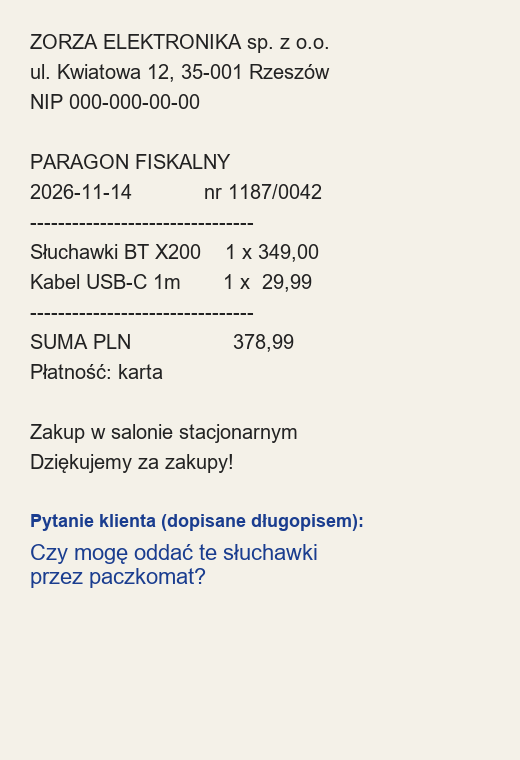

Na podstawie obrazu można odczytać następujące informacje:

*   **Gdzie kupiono produkty:** W sklepie ZORZA ELEKTRONIKA sp. z o.o. przy ul. Kwiatowej 12 w Rzeszowie (zakup dokonany w salonie stacjonarnym).
*   **Co kupiono:** Słuchawki BT X200 oraz kabel USB-C 1m.
*   **Jakie pytanie ma klient:** „Czy mogę oddać te słuchawki przez paczkomat?”


In [13]:
import base64
from IPython.display import Image, display
img_path = "../data/examples/paragon_pytanie.png"; display(Image(img_path, width=260))
b64 = base64.b64encode(open(img_path, "rb").read()).decode()
r = client.chat.completions.create(model=LLM, max_tokens=300, temperature=0.1, extra_body={"reasoning_effort": "none"},
    messages=[{"role": "user", "content": [
        {"type": "text", "text": "Odczytaj z obrazu: gdzie kupiono produkty, co kupiono i jakie pytanie ma klient?"},
        {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{b64}"}}]}])
print(r.choices[0].message.content)

## Wnioski
* **konfiguracja serwera**: bez parametrów w zapytaniu llama.cpp losuje z ustawieniami zapisanymi w pliku GGUF
  Gemmy (temperature 1.0, top_k 64, top_p 0.95), więc aplikacja zawsze przekazuje własne wartości.
* **temperature** steruje różnorodnością: przy T=0 wszystkie 4 próby dają tę samą odpowiedź, przy T=0.4 są 3 różne,
  od T=0.8 każda jest inna, a bogactwo słownictwa (TTR) rośnie do T=1.2. W odpowiedziach RAG używamy T=0.2 (fakty,
  powtarzalność), w generowaniu danych treningowych T=1.0 (różnorodność).
* **seed** zapewnia powtarzalność nawet przy T=1.0: ten sam seed dał identyczne hasło, inny seed inne.
  W ewaluacji seed jest stały.
* **top_k / top_p** ograniczają pulę losowanych tokenów: `top_k=1` i `top_p=0.3` dały 1 odpowiedź na 4 próby
  mimo T=1.2, a `top_p=1.0` cztery różne.
* **max_tokens** ucina odpowiedź (`finish_reason="length"` przy 20 i 80 tokenach), limit trzeba dobrać do zadania.
* **reasoning_effort**: z rozumowaniem prosta zagadka zajęła 2,6 s i 202 tokeny zamiast 0,24 s i 7 tokenów,
  a wynik (19,99 zł) był ten sam. Przy `max_tokens=30` cały limit poszedł na myślenie i treść była pusta.
  **thinking_budget_tokens** skraca rozumowanie, ale zbyt mały budżet bywa szkodliwy: przy 64 tokenach myślenie
  zostało ucięte w połowie i model dokończył je w treści odpowiedzi (po angielsku). Dlatego budżety poziomów
  w aplikacji są duże (2048 do 8192), a w pipeline'ie FAQ rozumowanie jest wyłączone.
* **repeat_penalty** w tym eksperymencie nie zmienił wyraźnie wyniku (9 i 8 różnych początków linii):
  przy niskiej temperaturze i krótkiej liście model sam unika powtórzeń; kara ma znaczenie przy długich tekstach.
* **embeddingi bge-m3** dobrze oddają znaczenie po polsku (parafrazy mają wyraźnie wyższe podobieństwo niż zdania
  o innym temacie): to podstawa wyszukiwania semantycznego w etapie 2.
* **obraz**: model z projektorem `mmproj` poprawnie odczytuje paragon i pytanie klienta (wielomodalność, próg 3.5).